# TFR Analysis

## setup

In [15]:
import sys
import numpy as np
from pathlib import Path
import importlib                               

# folder that contains tfr_functions.py
sys.path.append(r"C:\Users\ar687\Documents\GitHub\AmirSpikeinterface\main")
import tfr_functions as tfx
importlib.reload(tfs) 

NameError: name 'tfs' is not defined

## Settings

In [2]:
CONFIG = {
    # paths
    "recording_path": r"O:\archive\projects\2020_euSNN\Neuropixels_RT_mPFC\data\2_processed\20260522_r0000136_wt_1750\amir_data\down_sampled\1000_Hz",
    "session_dir":     r"O:\archive\projects\2020_euSNN\Neuropixels_RT_mPFC\data\2_processed\20260522_r0000136_wt_1750",
    "behavior_csv":    r"\share\trials.csv",   # appended to session_dir


    # channels
    "channel_id":      "imec0.ap#AP49",           # channel for the single-channel plots
    "channel_step": 20,                          # across-channels plot: use every Nth channel

    #trial selection
    "outcome":    "correct",   # "correct" or "incorrect"
    "trial_type": "long",   

    # common baseline: None = ALL trials (pre-Press). Or a list like [("correct","short"), ("correct","long")]
    "baseline_conditions": None,   

    #alignments
    "events": {
        "Press":   "press_np_s",
        "Tone":    "tone_np_s",
        "Release": "release_np_s",
    },

    #baseline evemt
    "baseline_event": "Press",   # which event's pre-window is used for the event baseline

    #extraction window (must be wide enough for lowest freq/n_cycles combo)
    "tmin": -3,
    "tmax": 3,

    # baseline & crop windows
    "baseline_window": (-0.5, -0.2),
    "crop_window":      (-0.6, 3),


    #frequency bands: each with its own n_cycles
    "band_settings": [
        {"freqs": np.arange(1, 4, 1),    "n_cycles": 2},   # delta
        {"freqs": np.arange(4, 8, 1),    "n_cycles": 5},   # theta
        {"freqs": np.arange(8, 13, 1),   "n_cycles": 6},   # alpha
        {"freqs": np.arange(13, 30, 1),  "n_cycles": 7},   # beta
        {"freqs": np.arange(30, 100, 1), "n_cycles": 10},  # gamma
    ],

     # band for the single-line plot: change this + channel_id
    "band": "alpha",
    "band_ranges": {"delta": (1, 3), "theta": (4, 8), "alpha": (8, 12),
                    "beta": (13, 29), "gamma": (30, 99)},

    "oscillation_boundaries": [4, 8, 13, 30],  

    #full-range plot
    "full_freq_range": (1, 99),
    "full_yticks": [1, 4, 8, 13, 20, 30, 40, 50, 60, 70, 80, 90, 99],

    # zoomed-in plot
    "zoom_freq_range": (1, 15),
    "zoom_yticks": list(range(1, 16)),

    #color bar
    "vmax":      0.5,    # color limit for the full-range and across-channels plots
    "zoom_vmax": 0.5,    # color limit for the zoomed plot 

    # labelling
    "analysis_label": "raw",   # free text, appended to titles/filenames

    #saving
    "save": True,   # set True to save PNGs
    "save_dir": r"O:\archive\projects\2020_euSNN\Neuropixels_RT_mPFC\data\2_processed\20260522_r0000136_wt_1750\amir_data\TFR\raw",
}

#CONFIG["save"] = False

event_names = list(CONFIG["events"].keys())

In [3]:
# LOAD DATA
ds_data = tfx.load_recording(CONFIG["recording_path"])
fs = ds_data.get_sampling_frequency()
beh, l_C = tfx.load_behavior(CONFIG["session_dir"], CONFIG["behavior_csv"],
                             CONFIG["outcome"], CONFIG["trial_type"])
CONFIG["n_trials"] = len(l_C)  

Total trials: 203
correct trials: 91
long trials: 126
long AND correct trials: 55


In [4]:
#  SINGLE-CHANNEL EXTRACTION + BASELINING 
raw_power = tfx.extract_raw_power(
    ds_data, l_C, CONFIG["channel_id"], CONFIG["events"], CONFIG["band_settings"],
    CONFIG["tmin"], CONFIG["tmax"], fs,
)

results_own, times_v2, freqs_v2 = tfx.compute_own_baseline(
    raw_power, CONFIG["band_settings"], CONFIG["baseline_window"], CONFIG["crop_window"],
)

results_baseline, _, _ = tfx.compute_event_baseline(
    raw_power, CONFIG["band_settings"], CONFIG["baseline_window"], CONFIG["crop_window"],
    CONFIG["baseline_event"],
)

Press: 55 valid trials, [(1, 3, 6000), (1, 4, 6000), (1, 5, 6000), (1, 17, 6000), (1, 70, 6000)]
Tone: 55 valid trials, [(1, 3, 6000), (1, 4, 6000), (1, 5, 6000), (1, 17, 6000), (1, 70, 6000)]
Release: 55 valid trials, [(1, 3, 6000), (1, 4, 6000), (1, 5, 6000), (1, 17, 6000), (1, 70, 6000)]
Applying baseline correction (mode: logratio)
Applying baseline correction (mode: logratio)
Applying baseline correction (mode: logratio)
Applying baseline correction (mode: logratio)
Applying baseline correction (mode: logratio)
Applying baseline correction (mode: logratio)
Applying baseline correction (mode: logratio)
Applying baseline correction (mode: logratio)
Applying baseline correction (mode: logratio)
Applying baseline correction (mode: logratio)
Applying baseline correction (mode: logratio)
Applying baseline correction (mode: logratio)
Applying baseline correction (mode: logratio)
Applying baseline correction (mode: logratio)
Applying baseline correction (mode: logratio)


c:\Users\ar687\Documents\GitHub\AmirAnalysis\main\tfr_functions.py:150: RuntimeWarning: tmax is not in time interval. tmax is set to <class 'mne.time_frequency.tfr.AverageTFR'>.tmax (2.999 s)
  power.crop(tmin=crop_window[0], tmax=crop_window[1])
c:\Users\ar687\Documents\GitHub\AmirAnalysis\main\tfr_functions.py:150: RuntimeWarning: tmax is not in time interval. tmax is set to <class 'mne.time_frequency.tfr.AverageTFR'>.tmax (2.999 s)
  power.crop(tmin=crop_window[0], tmax=crop_window[1])
c:\Users\ar687\Documents\GitHub\AmirAnalysis\main\tfr_functions.py:150: RuntimeWarning: tmax is not in time interval. tmax is set to <class 'mne.time_frequency.tfr.AverageTFR'>.tmax (2.999 s)
  power.crop(tmin=crop_window[0], tmax=crop_window[1])
c:\Users\ar687\Documents\GitHub\AmirAnalysis\main\tfr_functions.py:150: RuntimeWarning: tmax is not in time interval. tmax is set to <class 'mne.time_frequency.tfr.AverageTFR'>.tmax (2.999 s)
  power.crop(tmin=crop_window[0], tmax=crop_window[1])
c:\Users\ar6

## One channel Plot 

Saved: O:\archive\projects\2020_euSNN\Neuropixels_RT_mPFC\data\2_processed\20260522_r0000136_wt_1750\amir_data\TFR\raw\correct_long_imec0.ap#AP49_full.png


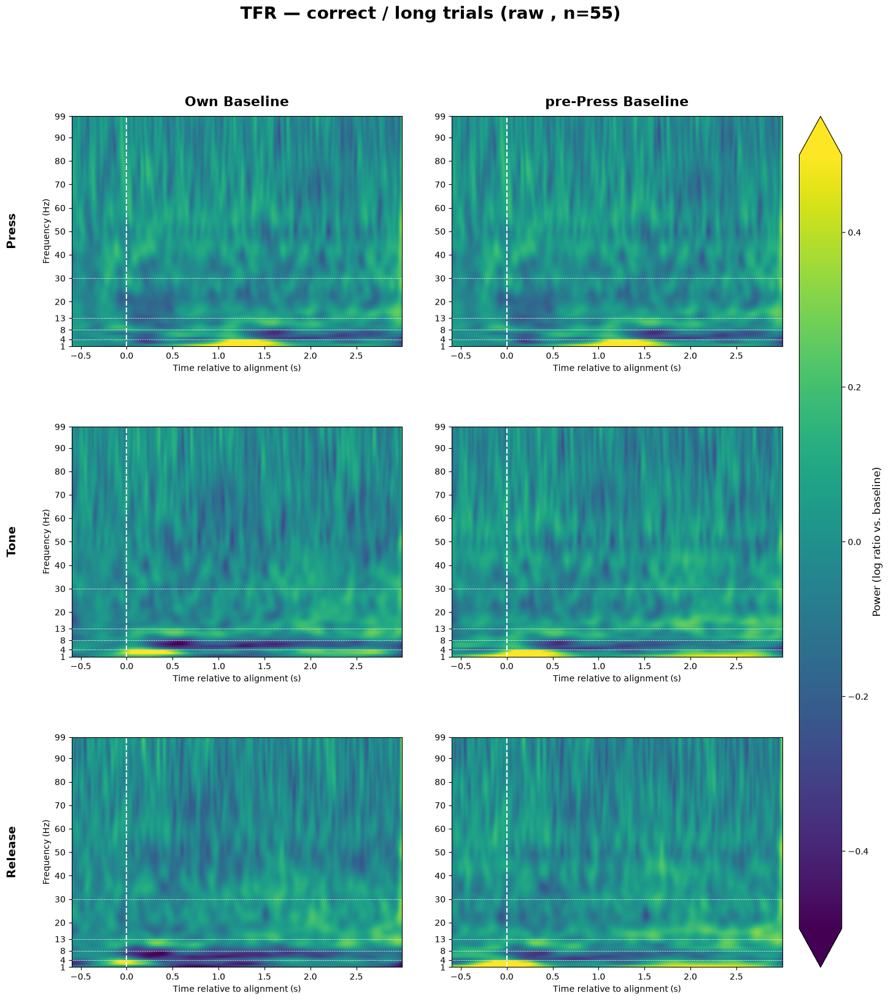

In [5]:
#  PLOT 1 — TFR compare, FULL frequency range
tfx.plot_tfr_compare(
    results_own, results_baseline, times_v2, freqs_v2, event_names,
    CONFIG["baseline_event"],
    title=tfx.make_title(CONFIG),
    freq_range=CONFIG["full_freq_range"], yticks=CONFIG["full_yticks"],
    band_boundaries=CONFIG["oscillation_boundaries"],
    vmax=CONFIG["vmax"],
    save_path=tfx.make_save_path(CONFIG, f"{CONFIG['channel_id']}_full"),
)

Saved: O:\archive\projects\2020_euSNN\Neuropixels_RT_mPFC\data\2_processed\20260522_r0000136_wt_1750\amir_data\TFR\raw\correct_long_imec0.ap#AP49_zoom.png


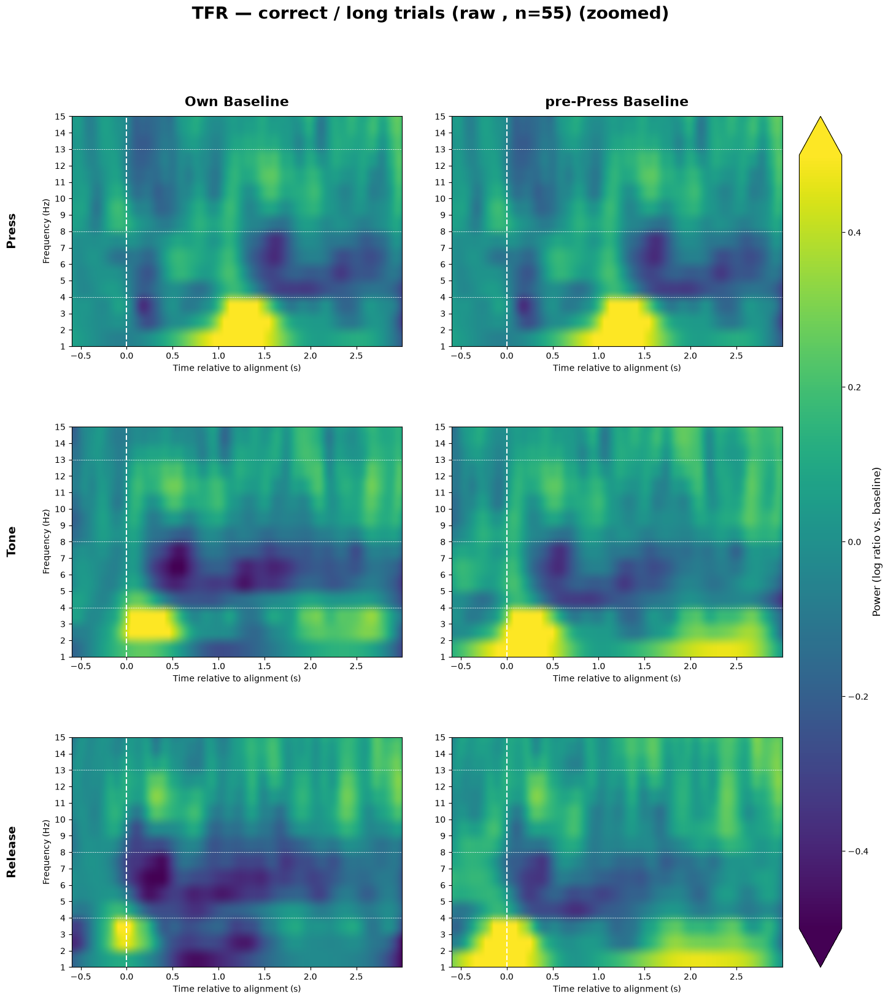

In [6]:

#  PLOT 2 — TFR compare, ZOOMED frequency range
tfx.plot_tfr_compare(
    results_own, results_baseline, times_v2, freqs_v2, event_names,
    CONFIG["baseline_event"],
    title=tfx.make_title(CONFIG, extra="(zoomed)"),
    freq_range=CONFIG["zoom_freq_range"], yticks=CONFIG["zoom_yticks"],
    band_boundaries=CONFIG["oscillation_boundaries"],
    vmax=CONFIG["zoom_vmax"],
    save_path=tfx.make_save_path(CONFIG, f"{CONFIG['channel_id']}_zoom"),
)

## Across-channels plot (Full frequency range)

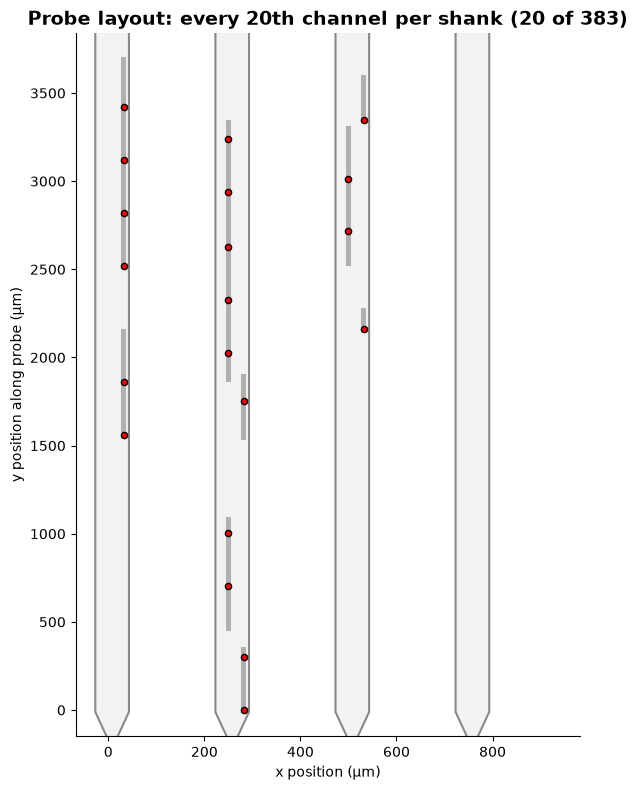

In [7]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Polygon

step = CONFIG["channel_step"]
probe = ds_data.get_probe()
all_loc = ds_data.get_channel_locations()

probe_df = pd.DataFrame({"channel_id": ds_data.get_channel_ids(), "x": all_loc[:, 0], "y": all_loc[:, 1]})
probe_df["shank"] = ((probe_df["x"] + 125) // 250).astype(int)
probe_df = probe_df.sort_values(["shank", "y", "x"]).reset_index(drop=True)
selected_df = probe_df[probe_df.groupby("shank").cumcount() % step == 0].reset_index(drop=True)
sel_loc = selected_df[["x", "y"]].values

fig, ax = plt.subplots(figsize=(6, 8))

contour = probe.probe_planar_contour
if contour is not None:
    ax.add_patch(Polygon(contour, closed=True, facecolor='#f2f2f2', edgecolor='#888888', linewidth=1.5, zorder=0))

ax.scatter(all_loc[:, 0], all_loc[:, 1], s=14, marker='s', color='#b0b0b0', edgecolors='none', zorder=2)

ax.scatter(sel_loc[:, 0], sel_loc[:, 1], s=20, color='red', edgecolors='black', linewidths=1, zorder=10)

ax.set_xlim(all_loc[:, 0].min() - 100, all_loc[:, 0].max() + 450)
ax.set_ylim(all_loc[:, 1].min() - 150, all_loc[:, 1].max() + 150)
ax.set_xlabel('x position (µm)')
ax.set_ylabel('y position along probe (µm)')
ax.set_title(f"Probe layout: every {step}th channel per shank ({len(sel_loc)} of {len(all_loc)})", fontsize=14, fontweight='bold')
for side in ['top', 'right']:
    ax.spines[side].set_visible(False)
ax.grid(False)

plt.tight_layout()
plt.show()

In [8]:
#  ACROSS-CHANNELS EXTRACTION + BASELINING
all_results, times_multi, freqs_multi = tfx.extract_and_baseline_multichannel(
    ds_data, l_C, selected_df["channel_id"].tolist(), CONFIG["events"],
    CONFIG["band_settings"], CONFIG["tmin"], CONFIG["tmax"], fs,
    CONFIG["baseline_window"], CONFIG["crop_window"], CONFIG["baseline_event"],
)

Press: 55 valid trials, [(1, 3, 6000), (1, 4, 6000), (1, 5, 6000), (1, 17, 6000), (1, 70, 6000)]
Tone: 55 valid trials, [(1, 3, 6000), (1, 4, 6000), (1, 5, 6000), (1, 17, 6000), (1, 70, 6000)]
Release: 55 valid trials, [(1, 3, 6000), (1, 4, 6000), (1, 5, 6000), (1, 17, 6000), (1, 70, 6000)]
Done: imec0.ap#AP257
Press: 55 valid trials, [(1, 3, 6000), (1, 4, 6000), (1, 5, 6000), (1, 17, 6000), (1, 70, 6000)]
Tone: 55 valid trials, [(1, 3, 6000), (1, 4, 6000), (1, 5, 6000), (1, 17, 6000), (1, 70, 6000)]
Release: 55 valid trials, [(1, 3, 6000), (1, 4, 6000), (1, 5, 6000), (1, 17, 6000), (1, 70, 6000)]
Done: imec0.ap#AP345
Press: 55 valid trials, [(1, 3, 6000), (1, 4, 6000), (1, 5, 6000), (1, 17, 6000), (1, 70, 6000)]
Tone: 55 valid trials, [(1, 3, 6000), (1, 4, 6000), (1, 5, 6000), (1, 17, 6000), (1, 70, 6000)]
Release: 55 valid trials, [(1, 3, 6000), (1, 4, 6000), (1, 5, 6000), (1, 17, 6000), (1, 70, 6000)]
Done: imec0.ap#AP145
Press: 55 valid trials, [(1, 3, 6000), (1, 4, 6000), (1, 5, 6

Saved: O:\archive\projects\2020_euSNN\Neuropixels_RT_mPFC\data\2_processed\20260522_r0000136_wt_1750\amir_data\TFR\raw\correct_long_across_channels.png


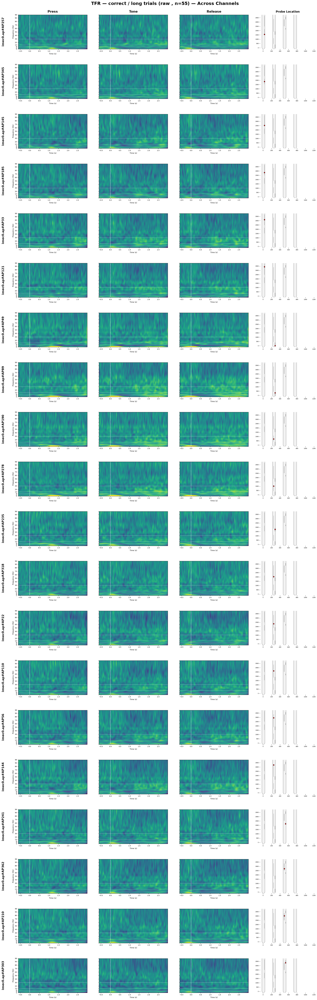

In [9]:

#  PLOT 3 — TFR across channels
tfx.plot_across_channels(
    all_results, times_multi, freqs_multi, event_names, selected_df, probe_df,
    CONFIG["baseline_event"],
    title=tfx.make_title(CONFIG, extra="— Across Channels"),
    freq_range=CONFIG["full_freq_range"], yticks=CONFIG["full_yticks"],
    band_boundaries=CONFIG["oscillation_boundaries"],
    vmax=CONFIG["vmax"],
    contour=probe.probe_planar_contour,
    save_path=tfx.make_save_path(CONFIG, "across_channels"),
)

Saved: O:\archive\projects\2020_euSNN\Neuropixels_RT_mPFC\data\2_processed\20260522_r0000136_wt_1750\amir_data\TFR\raw\correct_long_across_channels_zoom.png


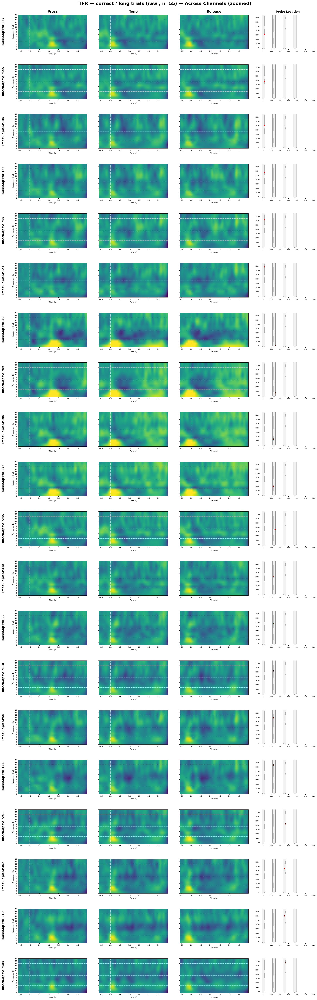

In [10]:

# PLOT 4 — TFR across channels, ZOOMED frequency range
tfx.plot_across_channels(
    all_results, times_multi, freqs_multi, event_names, selected_df, probe_df,
    CONFIG["baseline_event"],
    title=tfx.make_title(CONFIG, extra="— Across Channels (zoomed)"),
    freq_range=CONFIG["zoom_freq_range"], yticks=CONFIG["zoom_yticks"],
    band_boundaries=CONFIG["oscillation_boundaries"],
    vmax=CONFIG["zoom_vmax"],
    contour=probe.probe_planar_contour,
    save_path=tfx.make_save_path(CONFIG, "across_channels_zoom"),
)

Saved: O:\archive\projects\2020_euSNN\Neuropixels_RT_mPFC\data\2_processed\20260522_r0000136_wt_1750\amir_data\TFR\raw\correct_long_imec0.ap#AP49_bandlines.png


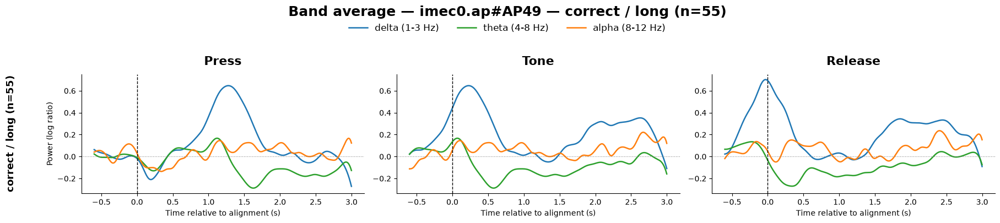

In [11]:
#extracted from the across-channels plot

BANDS = ["delta", "theta", "alpha"]  
CH    = CONFIG["channel_id"]                            
YLIM  = None                                            


if CH not in all_results:
    raise ValueError(f"{CH} was not in the across-channels selection. Options: {list(all_results)}")

label = f"{CONFIG['outcome']} / {CONFIG['trial_type']}"

tfx.plot_conditions_band_lines(
    {label: all_results[CH]},               
    {label: CONFIG["n_trials"]},
    times_multi, freqs_multi, event_names, CONFIG["band_ranges"],
    title=f"Band average — {CH} — {label} (n={CONFIG['n_trials']})",
    bands=BANDS, ylim=YLIM,
    save_path=tfx.make_save_path(CONFIG, f"{CH}_bandlines"))

## Same Baseline across different conditions

Pooled baseline trials: 91
Press: 90 valid trials, [(1, 3, 6000), (1, 4, 6000), (1, 5, 6000), (1, 17, 6000), (1, 70, 6000)]
Total trials: 203
correct trials: 91
short trials: 77
short AND correct trials: 36
Press: 35 valid trials, [(1, 3, 6000), (1, 4, 6000), (1, 5, 6000), (1, 17, 6000), (1, 70, 6000)]
Tone: 35 valid trials, [(1, 3, 6000), (1, 4, 6000), (1, 5, 6000), (1, 17, 6000), (1, 70, 6000)]
Release: 35 valid trials, [(1, 3, 6000), (1, 4, 6000), (1, 5, 6000), (1, 17, 6000), (1, 70, 6000)]
Total trials: 203
correct trials: 91
long trials: 126
long AND correct trials: 55
Press: 55 valid trials, [(1, 3, 6000), (1, 4, 6000), (1, 5, 6000), (1, 17, 6000), (1, 70, 6000)]
Tone: 55 valid trials, [(1, 3, 6000), (1, 4, 6000), (1, 5, 6000), (1, 17, 6000), (1, 70, 6000)]
Release: 55 valid trials, [(1, 3, 6000), (1, 4, 6000), (1, 5, 6000), (1, 17, 6000), (1, 70, 6000)]
Saved: O:\archive\projects\2020_euSNN\Neuropixels_RT_mPFC\data\2_processed\20260522_r0000136_wt_1750\amir_data\TFR\raw\compare_

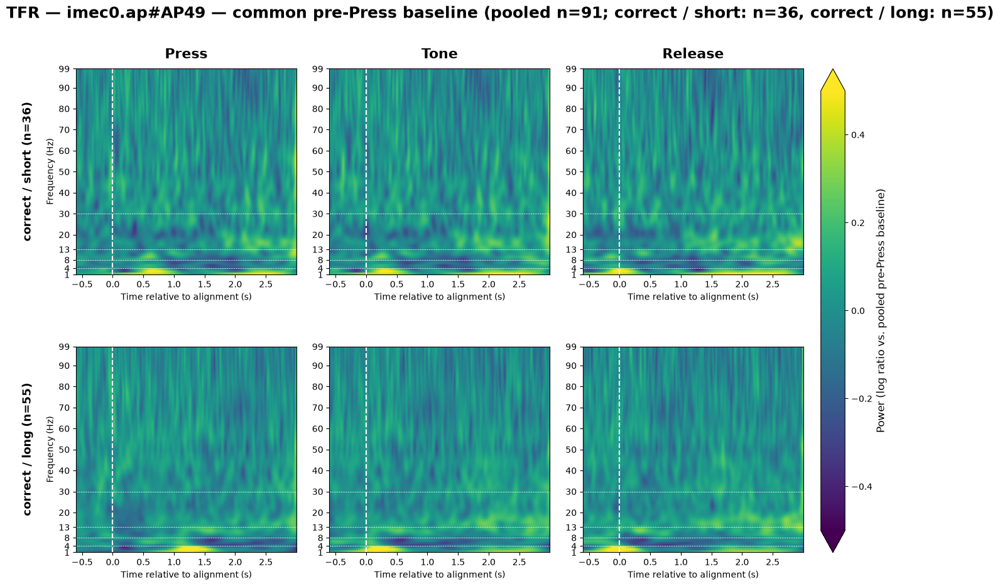

In [12]:
COMPARE_CONDITIONS = [("correct", "short"), ("correct", "long")]

res_cmp, n_cmp, pooled_cmp, t_cmp, f_cmp = tfx.compute_conditions_common_baseline(
    ds_data, CONFIG["session_dir"], CONFIG["behavior_csv"], COMPARE_CONDITIONS,
    CONFIG["channel_id"], CONFIG["events"], CONFIG["band_settings"],
    CONFIG["tmin"], CONFIG["tmax"], fs,
    CONFIG["baseline_window"], CONFIG["crop_window"], CONFIG["baseline_event"])

n_txt = ", ".join(f"{k}: n={v}" for k, v in n_cmp.items())
title = (f"TFR — {CONFIG['channel_id']} — common pre-Press baseline "
         f"(pooled n={len(pooled_cmp)}; {n_txt})")
fname = ("compare_" + "_vs_".join(f"{o}-{t}" for o, t in COMPARE_CONDITIONS)
         + f"_{CONFIG['channel_id']}")

tfx.plot_conditions_compare(
    res_cmp, n_cmp, t_cmp, f_cmp, event_names, title,
    freq_range=CONFIG["full_freq_range"], yticks=CONFIG["full_yticks"],
    band_boundaries=CONFIG["oscillation_boundaries"], vmax=CONFIG["vmax"],
    save_path=tfx.make_save_path_named(CONFIG, fname))

Saved: O:\archive\projects\2020_euSNN\Neuropixels_RT_mPFC\data\2_processed\20260522_r0000136_wt_1750\amir_data\TFR\raw\compare_correct-short_vs_correct-long_imec0.ap#AP49.png


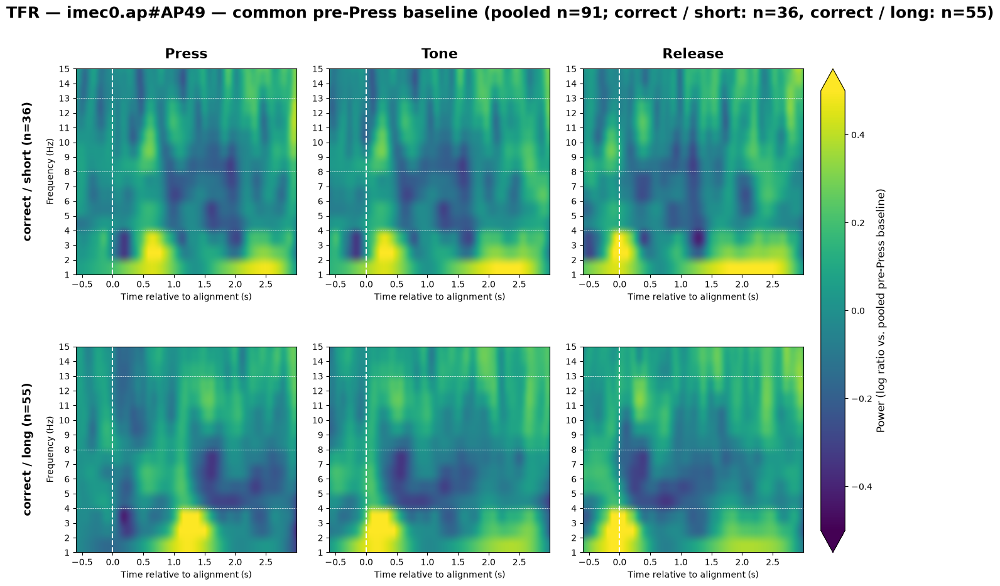

In [13]:
tfx.plot_conditions_compare(
    res_cmp, n_cmp, t_cmp, f_cmp, event_names, title,
    freq_range=CONFIG["zoom_freq_range"], yticks=CONFIG["zoom_yticks"],
    band_boundaries=CONFIG["oscillation_boundaries"], vmax=CONFIG["zoom_vmax"],
    save_path=tfx.make_save_path_named(CONFIG, fname))

Saved: O:\archive\projects\2020_euSNN\Neuropixels_RT_mPFC\data\2_processed\20260522_r0000136_wt_1750\amir_data\TFR\raw\compare_correct-short_vs_correct-long_imec0.ap#AP49_bandlines.png


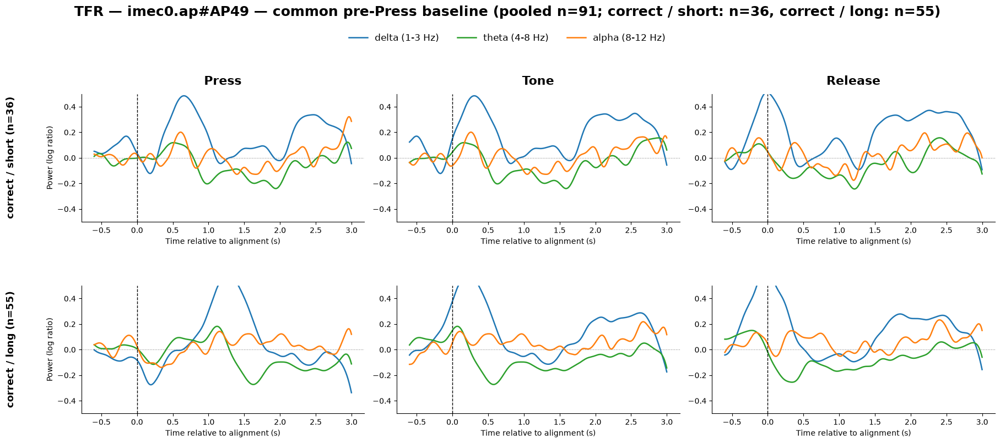

In [14]:
# extracted from the conditions-compare plot
tfx.plot_conditions_band_lines(
    res_cmp, n_cmp, t_cmp, f_cmp, event_names, CONFIG["band_ranges"],
    title=title,                      
    bands=["delta","theta", "alpha"],       
    ylim=(-0.5, 0.5),               
    save_path=tfx.make_save_path_named(CONFIG, fname + "_bandlines"))


# Permutation Test